# Does Austria's electricity forecast miss snowmaking?

Every afternoon, Austria's grid operator APG publishes a forecast of the next day's electricity use, hour by hour. Traders and the grid plan around it, so when it is wrong someone pays to fix the gap in real time.

Ski resorts make artificial snow on cold nights, mostly in November and early December. With all snow guns running, that is close to **900 MW**, roughly a tenth of Austria's night-time use ([Aigner, Steiger & Mayer, 2026](https://www.tandfonline.com/doi/full/10.1080/09669582.2026.2656746)). If APG's forecast left this out, it would be too low on exactly those nights.

**The test.** Cold nights also bring more heating, so "the forecast is too low on cold nights" would not prove anything on its own. What only snowmaking does is fade during the season: resorts build their snow base in November, and by mid-December most of it is done. So I compare the gap between cold and mild nights in **November** with the same gap on **11–20 December** (I stop before 21 December, when industry shuts down for Christmas). If the forecast misses snowmaking, the cold-night gap should be larger in November.

In [9]:
import io
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels.formula.api as smf

SEASONS = range(2010, 2023)   # winters covered by APG's forecast archive
COLD = -2.0                   # snow guns need roughly -2 °C or colder

## 1. Electricity: what Austria used, and what APG forecast

APG publishes both series free, as 15-minute values. The download is one ZIP that holds one ZIP per year. I average each hour and keep the **forecast error = actual − forecast**

**Which forecast.** This is the *day-ahead* forecast: APG publishes it the day before, and it is what the market and the grid plan with. Any error left on the day has to be balanced in real time, which costs money.

**Cleaning.** A few hours in APG's files are clearly broken, for example a load of about 100 MW when Austria never uses less than a few thousand. I drop every hour where the actual load or the forecast is below 3,000 MW and print how many that removes. Everything else is used as published.

In [10]:
APG_ACTUAL = "https://pb1-medien.apg.at/im/dl/apg-1191612034/Gesamtlast.zip"
APG_FORECAST = ("https://pb1-medien.apg.at/im/dl/apg-1333518940/"
                "Prognose%20%C3%BCber%20die%20Gesamtlast.zip")


def apg_hourly(url, file_tag):
    """Download one APG series and return hourly averages in MW, on Austrian local time."""
    outer = zipfile.ZipFile(io.BytesIO(requests.get(url, timeout=600).content))
    years = []
    for name in outer.namelist():
        if file_tag not in name or not name.endswith("_English.zip"):
            continue
        if int(name.split("_")[-2]) not in SEASONS:
            continue
        inner = zipfile.ZipFile(io.BytesIO(outer.read(name)))
        csv_name = next(n for n in inner.namelist() if n.lower().endswith(".csv"))
        df = pd.read_csv(io.BytesIO(inner.read(csv_name)))
        df.columns = ["start", "end", "mw"]
        # 'YYYY-MM-DD HH'; APG writes the repeated October hour as 2A and 2B
        hour = df["start"].str[:13].str.replace(r" 2[AB]$", " 02", regex=True)
        years.append(df.groupby(hour)["mw"].mean())
    series = pd.concat(years).groupby(level=0).mean()
    series.index = pd.to_datetime(series.index, format="%Y-%m-%d %H")
    return series.sort_index()


load = pd.DataFrame({
    "actual": apg_hourly(APG_ACTUAL, "Ist-Last_M15_"),
    "forecast": apg_hourly(APG_FORECAST, "Lastprognose_M15_"),
}).dropna()

broken = (load["actual"] < 3000) | (load["forecast"] < 3000)
print(f"Dropped {broken.sum()} broken hours out of {len(load):,}")
load = load[~broken]

load["error"] = load["actual"] - load["forecast"]
print(f"{len(load):,} hours, {load.index.min():%d %b %Y} to {load.index.max():%d %b %Y}")
load.describe().round(0)

Dropped 92 broken hours out of 113,939
113,847 hours, 01 Jan 2010 to 31 Dec 2022


,actual,forecast,error
count,113847.0,113847.0,113847.0
mean,6897.0,6841.0,57.0
std,1338.0,1276.0,484.0
min,3004.0,3013.0,-4620.0
25%,5847.0,5828.0,-202.0
50%,6820.0,6760.0,61.0
75%,7872.0,7748.0,336.0
max,10803.0,11895.0,3431.0


## 2. From hours to nights

Snow guns run at night, when it is coldest and electricity is cheapest, so the unit of the analysis is one night, not one hour.

- A night is **20:00 to 06:59**, eleven hours.
- It is labelled by the date of its evening, so the night of 3 to 4 November counts as 3 November.
- I average the forecast error over those hours and keep only nights with at least 10 of the 11 hours, so a gap in the data cannot distort a night.

Working with nights instead of hours also matters for the statistics: the 11 hours of one night are almost copies of each other, and counting them as 11 separate observations would make the result look far more precise than it is.

In [11]:
def night_average(hourly):
    """Average 20:00-06:59 values into one value per night, labelled by its evening's date."""
    night = hourly[(hourly.index.hour >= 20) | (hourly.index.hour <= 6)]
    evening = (night.index - pd.Timedelta(hours=7)).normalize()
    return night.groupby(evening).mean(), night.groupby(evening).size()


error, hours = night_average(load["error"])
nights = pd.DataFrame({"error": error[hours >= 10]})   # a full night has 11 hours
print(f"{len(nights):,} nights with load data")

4,737 nights with load data


## 3. Temperature in the mountains

Snow is made in the ski areas, not in Vienna, so the temperature has to come from the mountains.

- **Source:** GeoSphere Austria, the national weather service, whose station data is free and needs no account.
- **Stations:** the three highest stations in **Tyrol** and the three highest in **Salzburg**, the two states with most of the big ski areas, keeping only stations between 1,000 and 2,600 m that were already recording before 2010. The table below shows which six it picks.
- **Cold night:** the six stations' average night temperature is below **−2 °C**, about where snow guns can start.
- **Time zones:** GeoSphere records in UTC and APG in Austrian local time, so I convert before matching them, or every night would be shifted by one or two hours.

In [12]:
GS = "https://dataset.api.hub.geosphere.at/v1/station/historical/klima-v2-1h"

meta = pd.DataFrame(requests.get(f"{GS}/metadata", timeout=120).json()["stations"])
meta["altitude"] = pd.to_numeric(meta["altitude"], errors="coerce")
since = pd.to_datetime(meta["valid_from"], utc=True)
stations = (meta[meta["state"].isin(["Tirol", "Salzburg"])
                 & meta["altitude"].between(1000, 2600)
                 & (since < pd.Timestamp("2010-01-01", tz="UTC"))]
            .drop_duplicates("name")
            .sort_values("altitude", ascending=False)
            .groupby("state").head(3))
stations[["id", "name", "state", "altitude"]]

,id,name,state,altitude
725,17005,Ischgl-Idalpe,Tirol,2327.0
77,82,Rudolfshütte,Salzburg,2317.0
184,196,Patscherkofel,Tirol,2251.0
612,14305,Galzig,Tirol,2079.0
652,15310,Mooserboden,Salzburg,2036.0
80,85,Schmittenhöhe,Salzburg,1955.6


In [13]:
ids = ",".join(stations["id"].astype(str))
temps = []
for year in SEASONS:
    url = (f"{GS}?parameters=tl&station_ids={ids}&output_format=geojson"
           f"&start={year}-10-31T00:00&end={year}-12-21T12:00")
    reply = requests.get(url, timeout=600).json()
    # GeoSphere uses UTC; APG uses Austrian local time, so convert before joining
    times = (pd.to_datetime(reply["timestamps"], utc=True)
             .tz_convert("Europe/Vienna").tz_localize(None))
    per_station = [pd.Series(f["properties"]["parameters"]["tl"]["data"],
                             index=times, dtype=float)
                   for f in reply["features"]]
    temps.append(pd.concat(per_station, axis=1).mean(axis=1))

temp = pd.concat(temps)
nights["temp"] = night_average(temp)[0]
nights = nights.dropna()
print(f"{len(nights):,} nights with both load and temperature")

672 nights with both load and temperature


## 4. The two windows

The test compares two parts of the season:

- **November:** resorts are building their snow base, so on a cold night many snow guns run.
- **11–20 December:** most bases are built and many resorts are open, so far fewer guns run on a cold night.

I leave out **1–10 December**, which is in between, and everything from **21 December**, because the Christmas shutdown of industry changes the forecast error by itself and would drown out the effect I am looking for.

Inside each window every night is **cold** or **mild**. The table shows how many nights fall in each group over the 13 winters. I also note the week of each night: nights in the same week share the same weather and the same forecasting mistakes, which the statistics in step 6 have to allow for.

In [14]:
nights["season"] = nights.index.year
nights["weekday"] = nights.index.dayofweek
nights["cold"] = (nights["temp"] < COLD).astype(int)

november = nights.index.month == 11
mid_december = (nights.index.month == 12) & (nights.index.day >= 11) & (nights.index.day <= 20)
d = nights[november | mid_december].copy()
d["december"] = (d.index.month == 12).astype(int)
d["week"] = d.index.strftime("%Y-%W")   # nights in the same week are not independent

pd.crosstab(d["december"].map({0: "November", 1: "11-20 December"}),
            d["cold"].map({0: "mild", 1: "cold"}), margins=True)

cold,cold,mild,All
december,,,
11-20 December,76,53,129
November,151,236,387
All,227,289,516


## 5. First look

The chart averages the night forecast error in five-day blocks, from 1 November to 20 December, separately for cold and mild nights.

How to read it:

- A point **above zero** means the forecast was too low on those nights, on average.
- If the forecast missed snowmaking, the **blue line (cold nights)** would sit well above the orange one in November, the shaded blue area, and the two would come together by mid-December, the shaded orange area.
- The dashed line at 900 MW shows how far up the blue line would go if the forecast ignored every snow gun running at full power. It is an upper bound, since not every gun runs on every cold night.

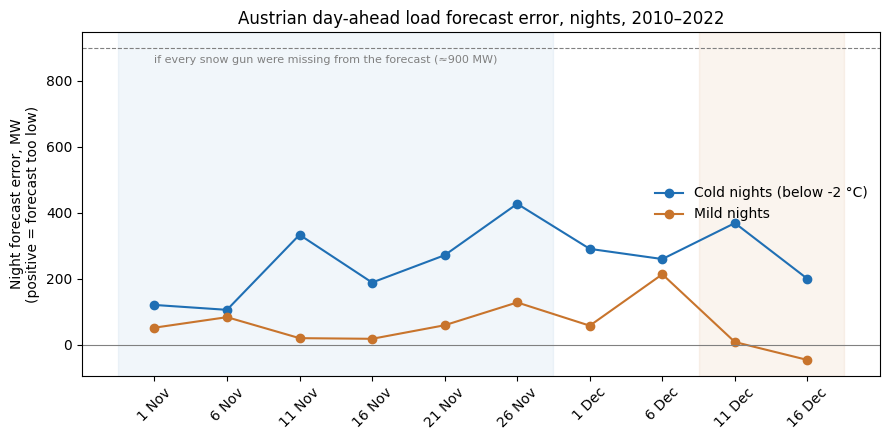

In [15]:
look = nights[(nights.index.month == 11)
              | ((nights.index.month == 12) & (nights.index.day <= 20))].copy()
day_of_season = np.where(look.index.month == 11, 0, 30) + look.index.day   # 1..50
look["block"] = (day_of_season - 1) // 5
look["group"] = np.where(look["cold"] == 1, "Cold nights (below -2 °C)", "Mild nights")
by_block = look.groupby(["block", "group"])["error"].mean().unstack()

labels = [f"{b * 5 + 1} Nov" if b < 6 else f"{b * 5 - 29} Dec" for b in by_block.index]
fig, ax = plt.subplots(figsize=(9, 4.5))
for group, colour in [("Cold nights (below -2 °C)", "#1f6fb4"), ("Mild nights", "#c8742c")]:
    ax.plot(labels, by_block[group], marker="o", color=colour, label=group)
ax.axhline(0, color="grey", linewidth=0.8)
ax.axhline(900, color="grey", linestyle="--", linewidth=0.8)
ax.text(0, 880, "if every snow gun were missing from the forecast (≈900 MW)",
        va="top", fontsize=8, color="grey")
ax.axvspan(-0.5, 5.5, color="#1f6fb4", alpha=0.06)
ax.axvspan(7.5, 9.5, color="#c8742c", alpha=0.08)
ax.set_ylabel("Night forecast error, MW\n(positive = forecast too low)")
ax.set_title("Austrian day-ahead load forecast error, nights, 2010–2022")
ax.legend(loc="center right", frameon=False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("results.png", dpi=150)
plt.show()

## 6. The test

The chart is noisy, so a regression on the 520 nights does the comparison properly:

`error = cold + cold × december + winter + weekday`

What each part does:

- **cold:** how much further the forecast falls short on a cold night than on a mild one, in November. This is the November gap.
- **cold × december:** how much that gap changes by 11–20 December. **This is the snowmaking test.** Heating happens in both windows and mostly cancels out; snowmaking mostly happens in November. If the forecast missed snowmaking, this number would be clearly negative.
- **winter:** some winters the forecast ran high or low overall, for example after a model change at APG. This compares nights within the same winter.
- **weekday:** use differs between weekdays and weekends, so this compares like with like.

**How sure.** The ± numbers are 95% ranges. They allow nights in the same week to be related, which makes them wider and more honest. The last line turns the precision into a size: the smallest November gap the test would find four times out of five. That says how strong a "no" is.

In [16]:
model = smf.ols("error ~ cold * december + C(season) + C(weekday)", data=d).fit(
    cov_type="cluster", cov_kwds={"groups": d["week"]})

V = model.cov_params()
gap_nov, se_nov = model.params["cold"], model.bse["cold"]
change, se_change = model.params["cold:december"], model.bse["cold:december"]
gap_dec = gap_nov + change
se_dec = np.sqrt(V.loc["cold", "cold"] + V.loc["cold:december", "cold:december"]
                 + 2 * V.loc["cold", "cold:december"])

print(f"Nights used: {int(model.nobs)}, in {d['week'].nunique()} weeks\n")
print(f"Cold-night gap, November:      {gap_nov:+6.0f} MW  (± {1.96 * se_nov:.0f})")
print(f"Cold-night gap, 11-20 December: {gap_dec:+6.0f} MW  (± {1.96 * se_dec:.0f})")
print(f"Change by mid-December:        {change:+6.0f} MW  (± {1.96 * se_change:.0f}), "
      f"p = {model.pvalues['cold:december']:.2f}")
print(f"\nSmallest November gap this test can reliably detect: about {2.8 * se_nov:.0f} MW")
print(f"Smallest change it can reliably detect:              about {2.8 * se_change:.0f} MW")

Nights used: 516, in 98 weeks

Cold-night gap, November:        +206 MW  (± 100)
Cold-night gap, 11-20 December:   +344 MW  (± 198)
Change by mid-December:          +137 MW  (± 236), p = 0.25

Smallest November gap this test can reliably detect: about 142 MW
Smallest change it can reliably detect:              about 337 MW


## How to read it

- **The November gap** is how much more the forecast falls short on a cold night than on a mild one. If APG missed snowmaking, it would be a large positive number, up to hundreds of MW.
- **The change by mid-December** is the snowmaking test itself. Heating is there in both windows; snowmaking mostly is not. A clearly negative change would point to snowmaking missing from the forecast. A change near zero, or positive, means whatever the forecast misses on cold nights does not fade with the snowmaking season, so it is more likely heating or cold weather in general.
- **The smallest detectable sizes** tell you how strong a "no" is. Compare them with the 900 MW of snowmaking at full power.

**Limits.** Six stations stand in for every ski area. Snow guns depend on humidity as well as temperature ("wet bulb"), which I ignore. Some resorts keep making snow in December, which would shrink the change and make a "no" less convincing.